# 1. Khởi tạo môi trường thực nghiệm

Import các thư viện dùng xuyên suốt notebook:
- **OpenCV (`cv2`)** để xử lý ảnh, phát hiện/ghép đặc trưng và ước lượng homography.
- **NumPy** để thao tác ma trận và mask.
- **Matplotlib** để trực quan hóa ảnh, keypoints, matches và panorama.
- **Pandas** để tổng hợp các chỉ số thành bảng; `time` để đo thời gian chạy; `os` để kiểm tra đường dẫn ảnh.

Hai ngưỡng được dùng thống nhất trong các lần chạy: Lowe's ratio test và ngưỡng sai số chiếu lại của RANSAC.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time
import pandas as pd
import os
import IPython.display as display
import sys

# Cau hinh cac tham so chuan cho bai thu nghiem
LOWE_RATIO_THRESH = 0.6
RANSAC_REPROJ_THRESH = 5.0
ALGORITHM = ["SIFT", "AKAZE", "ORB"]
BLENDING = ["OVERLAY", "AVERAGE", "FEATHER"]
MASK_RENDER = False

print("Libraries and const imported.")

Libraries and const imported.


# 2. Xây dựng các hàm xử lý ảnh dùng chung

Cell này định nghĩa pipeline và các hàm hỗ trợ, chưa chạy thí nghiệm trên bộ ảnh cụ thể:
- `extract_features`: chuyển ảnh sang grayscale, phát hiện keypoints và tính descriptors bằng SIFT, ORB hoặc AKAZE.
- `visualize_keypoints`: hiển thị vị trí và quy mô keypoints.
- `match_features`: ghép descriptors bằng khoảng cách phù hợp với từng thuật toán, sau đó lọc bằng Lowe's ratio test.
- `estimate_homography`: ước lượng ma trận homography bằng RANSAC và tính inlier ratio.
- `stitch_two_images` / `stitch_three_images`: đưa ảnh về cùng canvas và ghép bằng cách chồng ảnh theo mask.
- `images_stitching`: điều phối pipeline, tùy chọn hiển thị trung gian, đo thời gian và trả về các chỉ số.

**Lưu ý:** cách ghép hiện tại là overlay/chọn pixel theo thứ tự ưu tiên, chưa phải blending làm mượt vùng chồng lấp. Phần sau sẽ so sánh các cách blending trên cùng kết quả căn chỉnh.

In [2]:
# input image alorithm: SIFT, ORB, AKAZE
# output keypoints kp, descriptors des
def extract_features(image, algorithm='SIFT'):
    """
    Extract keypoints and descriptors from an image using SIFT, ORB, or AKAZE.
    """
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    if algorithm.upper() == 'SIFT':
        detector = cv2.SIFT_create()
    elif algorithm.upper() == 'ORB':
        detector = cv2.ORB_create(nfeatures=5000)
    elif algorithm.upper() == 'AKAZE':
        detector = cv2.AKAZE_create()
    else:
        raise ValueError(f"Unknown algorithm: {algorithm}")

    kp, des = detector.detectAndCompute(gray, None)
    return kp, des

def visualize_keypoints(images, keypoints_list, titles=None):
    """
    Visualize detected keypoints on multiple images.
    """
    n = len(images)

    if titles is None:
        titles = [f"Image {i + 1}" for i in range(n)]

    fig, axes = plt.subplots(1, n, figsize=(7 * n, 6))
    axes = np.atleast_1d(axes)

    for i, (image, keypoints) in enumerate(zip(images, keypoints_list)):
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        vis = cv2.drawKeypoints(
            gray,
            keypoints,
            None,
            flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS,
            color=(255, 0, 0)
        )

        vis = cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)
        axes[i].imshow(vis)
        axes[i].set_title(f"{titles[i]}\n{len(keypoints)} keypoints")
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

# input set of descriptors from two images, output list of good matches 
# ratio_thresh: threshold for Lowe's ratio test
# L2, HAMMING
# output good matches
def match_features(des1, des2, algorithm='SIFT', ratio_thresh=0.7):
    """
    Match descriptors from two images using appropriate distance metric and matcher.
    """
    if des1 is None or des2 is None or len(des1) == 0 or len(des2) == 0:
        return []

    if algorithm.upper() in ['SIFT', 'AKAZE']:
        # L2 norm for SIFT/AKAZE descriptors
        matcher = cv2.BFMatcher(cv2.NORM_L2)
    elif algorithm.upper() == 'ORB':
        # Hamming distance for binary ORB descriptors
        matcher = cv2.BFMatcher(cv2.NORM_HAMMING)
    else:
        raise ValueError(f"Unknown algorithm: {algorithm}")

    raw_matches = matcher.knnMatch(des1, des2, k=2)

    # Apply Lowe's ratio test
    good_matches = []
    for m, n in raw_matches:
        if m.distance < ratio_thresh * n.distance:
            good_matches.append(m)

    return good_matches

# input keypoints from two images and list of matches, 
# output homography matrix (H), mask of inliers, and inlier ratio
# meaning?
def estimate_homography(kp1, kp2, matches, reproj_thresh=5.0):
    """
    Estimate Homography matrix using RANSAC and keep track of inliers and metrics.
    """
    if len(matches) < 4:
        return None, None, 0.0

    src_pts = np.float32([kp1[m.queryIdx].pt for m in matches]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp2[m.trainIdx].pt for m in matches]).reshape(-1, 1, 2)

    H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, reproj_thresh)

    inliers_count = int(np.sum(mask)) if mask is not None else 0
    inlier_ratio = inliers_count / len(matches) if len(matches) > 0 else 0.0

    return H, mask, inlier_ratio

# input three images and two homography matrices, 
# output stitched image
def stitch_three_images(
    img1, img2, img3, H12, H32, blending="overlay"
):
    """
    Stitch three images aligned to the coordinate frame of img2.

    H12: Homography mapping img1 -> img2.
    H32: Homography mapping img3 -> img2.
    blending: 'overlay', 'average', or 'feather'.
    """
    if H12 is None or H32 is None:
        raise ValueError("H12 và H32 phải là homography hợp lệ.")

    h1, w1 = img1.shape[:2]
    h2, w2 = img2.shape[:2]
    h3, w3 = img3.shape[:2]

    # 1. Xác định corners của từng ảnh
    corners1 = np.float32([
        [0, 0], [0, h1 - 1],
        [w1 - 1, h1 - 1], [w1 - 1, 0]
    ]).reshape(-1, 1, 2)

    corners2 = np.float32([
        [0, 0], [0, h2 - 1],
        [w2 - 1, h2 - 1], [w2 - 1, 0]
    ]).reshape(-1, 1, 2)

    corners3 = np.float32([
        [0, 0], [0, h3 - 1],
        [w3 - 1, h3 - 1], [w3 - 1, 0]
    ]).reshape(-1, 1, 2)

    # 2. Chiếu corners về hệ tọa độ của img2
    warped_corners1 = cv2.perspectiveTransform(corners1, H12)
    warped_corners3 = cv2.perspectiveTransform(corners3, H32)

    all_corners = np.concatenate(
        [corners1 if False else corners2,
        warped_corners1, warped_corners3],
        axis=0
    )

    x_min, y_min = np.floor(
        all_corners.min(axis=0).ravel()
    ).astype(int)

    x_max, y_max = np.ceil(
        all_corners.max(axis=0).ravel()
    ).astype(int)

    tx, ty = max(0, -x_min), max(0, -y_min)

    T = np.array([
        [1, 0, tx],
        [0, 1, ty],
        [0, 0, 1]
    ], dtype=np.float64)

    size = (x_max - x_min + 1, y_max - y_min + 1)

    # 3. Warp cả 3 ảnh lên canvas chung
    H12_canvas = T @ H12
    H32_canvas = T @ H32

    canvas_img1 = cv2.warpPerspective(img1, H12_canvas, size)
    canvas_img2 = cv2.warpPerspective(img2, T, size)
    canvas_img3 = cv2.warpPerspective(img3, H32_canvas, size)

    # 4. Tạo mask từ vùng ảnh hợp lệ rồi warp lên canvas
    def warp_mask(img, H):
        h, w = img.shape[:2]
        src_mask = np.full((h, w), 255, dtype=np.uint8)
        return cv2.warpPerspective(
            src_mask, H, size,
            flags=cv2.INTER_NEAREST
        ) > 0

    mask1 = warp_mask(img1, H12_canvas)
    mask2 = warp_mask(img2, T)
    mask3 = warp_mask(img3, H32_canvas)

    masks = [mask1, mask2, mask3]
    canvases = [
        canvas_img1.astype(np.float32),
        canvas_img2.astype(np.float32),
        canvas_img3.astype(np.float32)
    ]

    # 5. Blending
    output = np.zeros_like(canvases[0])

    if blending == "OVERLAY":
        # Thứ tự ưu tiên: img3 -> img1 -> img2
        # img2 được đặt trên cùng, giữ nguyên hành vi cũ.
        for canvas, mask in zip(canvases, masks):
            output[mask] = canvas[mask]
            
        output[mask2] = canvas_img2[mask2]

    elif blending == "AVERAGE":
        # Trung bình các ảnh hợp lệ tại mỗi pixel
        weight_sum = np.zeros(size[::-1], dtype=np.float32)

        for canvas, mask in zip(canvases, masks):
            output[mask] += canvas[mask]
            weight_sum[mask] += 1.0

        valid = weight_sum > 0
        output[valid] /= weight_sum[valid, None]

    elif blending == "FEATHER":
        # Tính trọng số dựa trên khoảng cách tới biên mỗi ảnh
        numerator = np.zeros_like(output)
        denominator = np.zeros(size[::-1], dtype=np.float32)

        for canvas, mask in zip(canvases, masks):
            dist = cv2.distanceTransform(
                mask.astype(np.uint8), cv2.DIST_L2, 3
            )

            # Tránh trọng số bằng 0 tại biên
            weight = dist * mask.astype(np.float32)

            numerator += canvas * weight[:, :, None]
            denominator += weight

        # Fallback cho pixel hợp lệ nằm ngay trên biên ảnh
        zero_weight = (denominator == 0)
        for canvas, mask in zip(canvases, masks):
            fallback = zero_weight & mask
            numerator[fallback] += canvas[fallback]
            denominator[fallback] += 1.0

        valid = denominator > 0
        output[valid] = (
            numerator[valid] / denominator[valid, None]
        )

    if MASK_RENDER:
    # if True:
        overlap_count = (
            mask1.astype(np.uint8)
            + mask2.astype(np.uint8)
            + mask3.astype(np.uint8)
        )

        mask_vis = np.zeros_like(output)

        mask_vis[overlap_count == 1] = (255, 0, 0)
        mask_vis[overlap_count == 2] = (0, 255, 255)
        mask_vis[overlap_count == 3] = (0, 0, 255)

        output = cv2.addWeighted(
            output, 0.7,
            mask_vis, 0.3,
            0
        )

    return np.clip(output, 0, 255).astype(np.uint8)

def stitch_two_images(img1, img2, H12, blending):

    """
    Stitch two images aligned to the coordinate frame of the second image (img2).
    H12: Homography mapping img1 to img2 (dst: img2, src: img1)
    """
    h1, w1 = img1.shape[:2]
    h2, w2 = img2.shape[:2]

    # Corners of each image
    corners1 = np.float32([[0, 0], [0, h1], [w1, h1], [w1, 0]]).reshape(-1, 1, 2)
    corners2 = np.float32([[0, 0], [0, h2], [w2, h2], [w2, 0]]).reshape(-1, 1, 2)

    # Transform corners to the central frame (img2)
    warped_corners1 = cv2.perspectiveTransform(corners1, H12) if H12 is not None else corners1

    all_corners = np.concatenate((corners2, warped_corners1), axis=0)
    [x_min, y_min] = np.int32(all_corners.min(axis=0).ravel() - 0.5)
    [x_max, y_max] = np.int32(all_corners.max(axis=0).ravel() + 0.5)

    tx = -x_min if x_min < 0 else 0
    ty = -y_min if y_min < 0 else 0

    T = np.array([[1, 0, tx], [0, 1, ty], [0, 0, 1]], dtype=np.float32)

    output_w = x_max - x_min
    output_h = y_max - y_min

    # Warp all images to the common canvas
    canvas_img2 = cv2.warpPerspective(img2, T, (output_w, output_h))

    H12_translated = T.dot(H12) if H12 is not None else T
    canvas_img1 = cv2.warpPerspective(img1, H12_translated, (output_w, output_h))

    # Composite the images together (basic blending/overlay)
    # Mask regions
    src_mask1 = np.full((h1, w1), 255, dtype=np.uint8)
    src_mask2 = np.full((h2, w2), 255, dtype=np.uint8)

    mask1 = cv2.warpPerspective(
        src_mask1, H12_translated, (output_w, output_h),
        flags=cv2.INTER_NEAREST
    ) > 0

    mask2 = cv2.warpPerspective(
        src_mask2, T, (output_w, output_h),
        flags=cv2.INTER_NEAREST
    ) > 0

    only1 = mask1 & ~mask2
    only2 = mask2 & ~mask1
    overlap = mask1 & mask2

    output = np.zeros_like(canvas_img2)
    # Vùng chỉ có một ảnh: giữ nguyên pixel
    output[only1] = canvas_img1[only1]
    output[only2] = canvas_img2[only2]

    if blending == "OVERLAY":
        # Ảnh 2 nằm trên ảnh 1 ở vùng chồng lấp
        output[overlap] = canvas_img2[overlap]

    elif blending == "AVERAGE":
        # Trung bình pixel tại vùng chồng lấp
        output[overlap] = (
            0.5 * canvas_img1[overlap] +
            0.5 * canvas_img2[overlap]
        )

    elif blending == "FEATHER":
        # Trọng số lớn hơn cho pixel xa biên của mỗi ảnh
        dist1 = cv2.distanceTransform(
            mask1.astype(np.uint8), cv2.DIST_L2, 3
        )
        dist2 = cv2.distanceTransform(
            mask2.astype(np.uint8), cv2.DIST_L2, 3
        )

        denom = dist1 + dist2
        w1 = dist1 / (denom + 1e-6)
        w2 = dist2 / (denom + 1e-6)

        output[overlap] = (
            canvas_img1[overlap] * w1[overlap, None] +
            canvas_img2[overlap] * w2[overlap, None]
        )

    if MASK_RENDER:
        # if True:
        overlap_count = (
            mask1.astype(np.uint8)
            + mask2.astype(np.uint8)
        )
    
        mask_vis = np.zeros_like(output)

        mask_vis[overlap_count == 1] = (255, 0, 0)
        mask_vis[overlap_count == 2] = (0, 255, 255)

        output = cv2.addWeighted(
            output, 0.7,
            mask_vis, 0.3,
            0
        )

    return output

def images_stitching(img1, img2, algo='SIFT', verbose=True, blending="OVERLAY", img3=None, show_origin=False, show_keypoints=False, show_matches=False, show_panorama=True):    
    # Hien thi các ảnh
    isThree = img3 is not None

    if show_origin:
        fig, axes = plt.subplots(1, 3 if isThree else 2, figsize=(12, 6))
        axes[0].imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB))
        axes[0].set_title("Ảnh 1")
        axes[0].axis('off')

        axes[1].imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB))
        axes[1].set_title("Ảnh 2")
        axes[1].axis('off')

        if isThree:
            axes[2].imshow(cv2.cvtColor(img3, cv2.COLOR_BGR2RGB))
            axes[2].set_title("Ảnh 3")
            axes[2].axis('off')

        plt.tight_layout()
        plt.show()

    if verbose:
        print(f"\n{'='*25} {algo} {'='*25}")
    start_time = time.time()

    # 1. Feature Extraction
    kp1, des1 = extract_features(img1, algorithm=algo)
    kp2, des2 = extract_features(img2, algorithm=algo)
    if isThree:
        kp3, des3 = extract_features(img3, algorithm=algo)

    if show_keypoints:
        visualize_keypoints(
            [img1, img2, img3] if isThree else [img1, img2],
            [kp1, kp2, kp3] if isThree else [kp1, kp2],
            titles=['Image 1', 'Image 2', 'Image 3'] if isThree else ['Image 1', 'Image 2']
        )
    
    # 2. Feature Matching
    matches12 = match_features(
        des1, des2, algorithm=algo,
        ratio_thresh=LOWE_RATIO_THRESH
    )
    if isThree:
        matches32 = match_features(
            des3, des2, algorithm=algo,
            ratio_thresh=LOWE_RATIO_THRESH
        )

    if show_matches:
        img_matches = cv2.drawMatches(img1, kp1, img2, kp2, matches12[:50], None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
        plt.figure(figsize=(20, 10))
        plt.imshow(cv2.cvtColor(img_matches, cv2.COLOR_BGR2RGB))
        plt.title("Các cặp điểm khớp đặc trưng tiêu biểu")
        plt.axis('off')
        plt.show()

        if isThree:
            img_matches = cv2.drawMatches(img3, kp3, img2, kp2, matches32[:50], None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
            plt.figure(figsize=(20, 10))
            plt.imshow(cv2.cvtColor(img_matches, cv2.COLOR_BGR2RGB))
            plt.title("Các cặp điểm khớp đặc trưng tiêu biểu")
            plt.axis('off')
            plt.show()

    # 3. Homography Estimation
    H12, mask12, inlier_ratio12 = estimate_homography(
        kp1, kp2, matches12,
        reproj_thresh=RANSAC_REPROJ_THRESH
    )
    if isThree:
        H32, mask32, inlier_ratio32 = estimate_homography(
            kp3, kp2, matches32,
            reproj_thresh=RANSAC_REPROJ_THRESH
        )

    elapsed_time = time.time() - start_time

    inliers12 = int(np.sum(mask12)) if mask12 is not None else 0
    if isThree:
        inliers32 = int(np.sum(mask32)) if mask32 is not None else 0

    # 4. Display metrics immediately
    metrics = {
        'Metric': [
            'Keypoints',
            'Good Matches (1->2)',
            'Good Matches (3->2)',
            'RANSAC Inliers (1->2)',
            'RANSAC Inliers (3->2)',
            'Inlier Ratio (1->2)',
            'Inlier Ratio (3->2)',
            'Execution Time (s)'
        ],
        'Value': [
            [len(kp1), len(kp2), len(kp3)],
            len(matches12),
            len(matches32),
            inliers12,
            inliers32,
            f"{inlier_ratio12 * 100:.2f}%",
            f"{inlier_ratio32 * 100:.2f}%",
            round(elapsed_time, 4)
        ]
    } if isThree else {
        'Metric': [
            'Keypoints',
            'Good Matches (1->2)',
            'RANSAC Inliers (1->2)',
            'Inlier Ratio (1->2)',
            'Execution Time (s)'
        ],
        'Value': [
            [len(kp1), len(kp2)],
            len(matches12),
            inliers12,
            f"{inlier_ratio12 * 100:.2f}%",
            round(elapsed_time, 4)
        ]
    }

    # 5. Stitch and display panorama
    if isThree:
        panorama = stitch_three_images(img1, img2, img3, H12, H32, blending)
    else:
        panorama = stitch_two_images(img1, img2, H12, blending)

    if show_panorama:
        plt.figure(figsize=(16, 6))
        plt.imshow(cv2.cvtColor(panorama, cv2.COLOR_BGR2RGB))
        plt.title(f"Panorama generated by {algo}")
        plt.axis('off')
        plt.show()

    return metrics, panorama

print("Helper functions successfully defined.")


Helper functions successfully defined.


## 3.1. Nạp và kiểm tra bộ ảnh gốc

Đọc tối đa ba ảnh từ thư mục `input/` nếu các biến ảnh chưa tồn tại trong kernel, sau đó hiển thị chúng cạnh nhau. Đây là bước kiểm tra nhanh:
- các file ảnh có đúng đường dẫn và đọc thành công không;
- ba ảnh có cùng một cảnh và có vùng chồng lấp đủ lớn không;
- khác biệt về góc chụp/độ sáng có phù hợp để thử nghiệm stitching không.

Bộ ảnh này được dùng làm trường hợp cơ sở để so sánh SIFT, ORB và AKAZE.

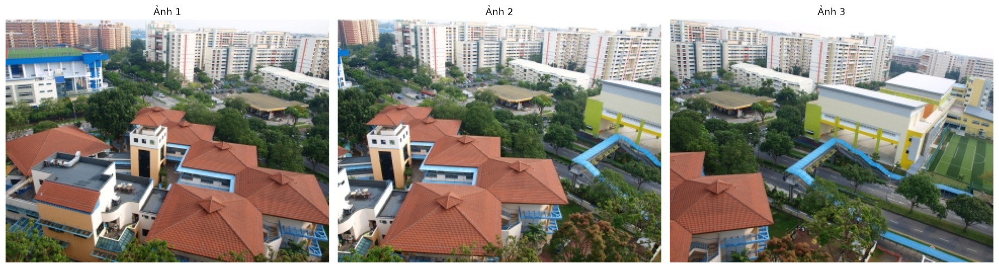

In [3]:
# Tu dong doc lai file anh nguon neu bien img1 hoac img2 chua duoc dinh nghia
img1_path = 'input/sample_01.jpg'
img2_path = 'input/sample_02.jpg'
img3_path = 'input/sample_03.jpg'

if 'img1' not in globals() and os.path.exists(img1_path):
    img1 = cv2.imread(img1_path)
if 'img2' not in globals() and os.path.exists(img2_path):
    img2 = cv2.imread(img2_path)
if 'img3' not in globals() and os.path.exists(img3_path):
    img3 = cv2.imread(img3_path)

sample_set = [img1, img2, img3]

# Hien thi truc quan ba anh thu nghiem
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB))
axes[0].set_title("Ảnh 1")
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB))
axes[1].set_title("Ảnh 2")
axes[1].axis('off')

axes[2].imshow(cv2.cvtColor(img3, cv2.COLOR_BGR2RGB))
axes[2].set_title("Ảnh 3")
axes[2].axis('off')

plt.tight_layout()
plt.show()

## 3.2. Benchmark thuật toán trên bộ ảnh gốc

Chạy pipeline lần lượt với **SIFT, ORB và AKAZE** trên cùng bộ ảnh. Với mỗi thuật toán, notebook hiển thị keypoints, matches và panorama, đồng thời thu thập:
- số keypoints và good matches;
- số RANSAC inliers và inlier ratio cho từng cặp ảnh;
- thời gian thực thi.

Kết quả được chuyển thành một dòng cho mỗi thuật toán và ghép vào `df_summary` để tiện đối chiếu. Khi diễn giải, không nên dùng riêng số matches để kết luận: cần xem thêm inlier ratio và chất lượng hình học/trực quan của panorama.


========================= SIFT =========================


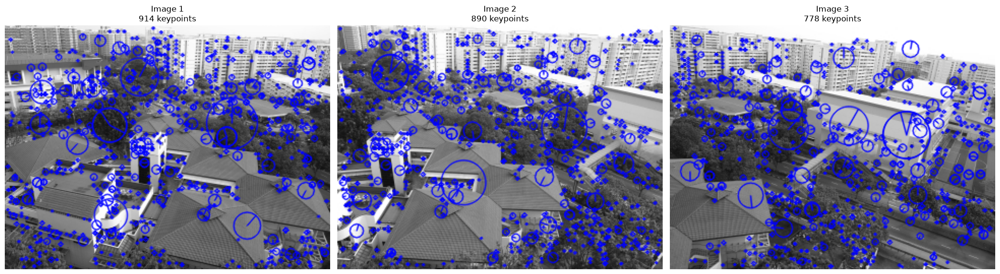

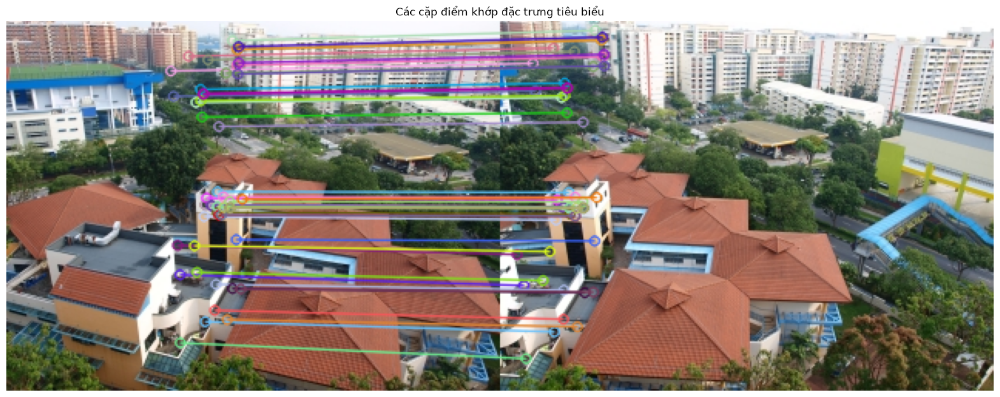

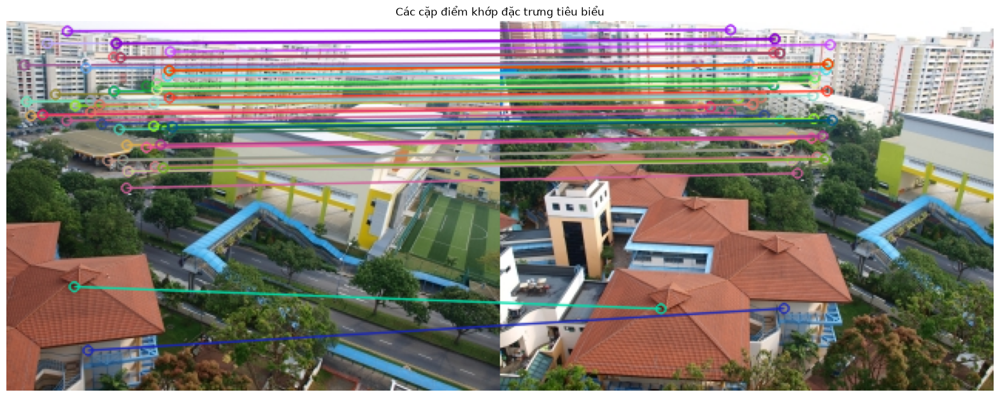

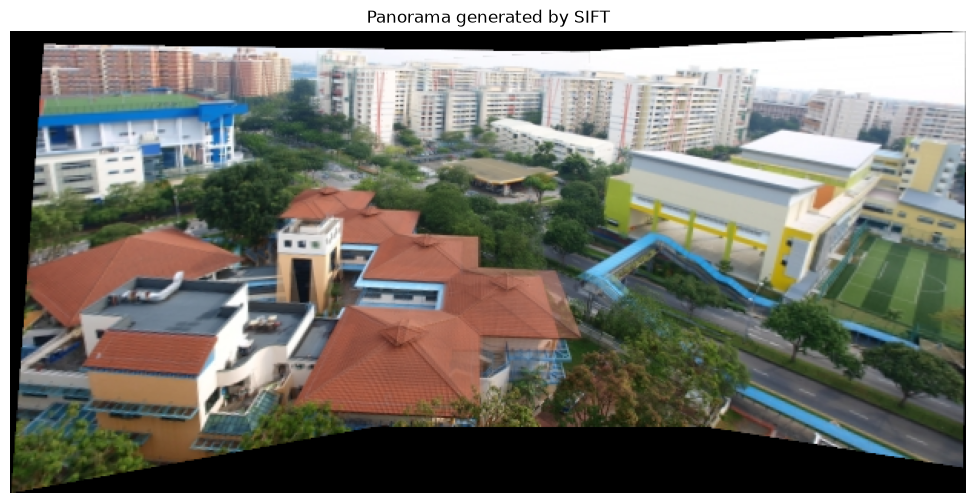


========================= ORB =========================


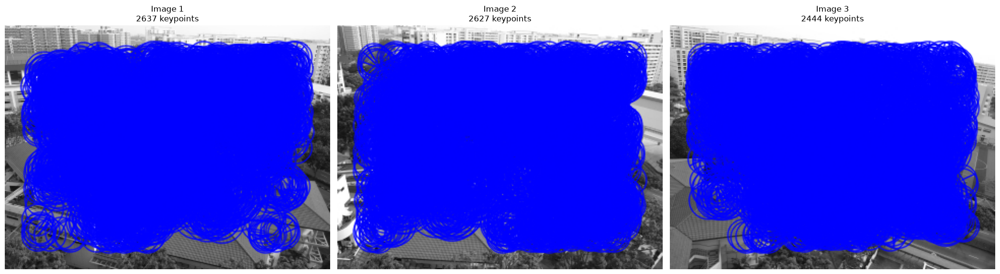

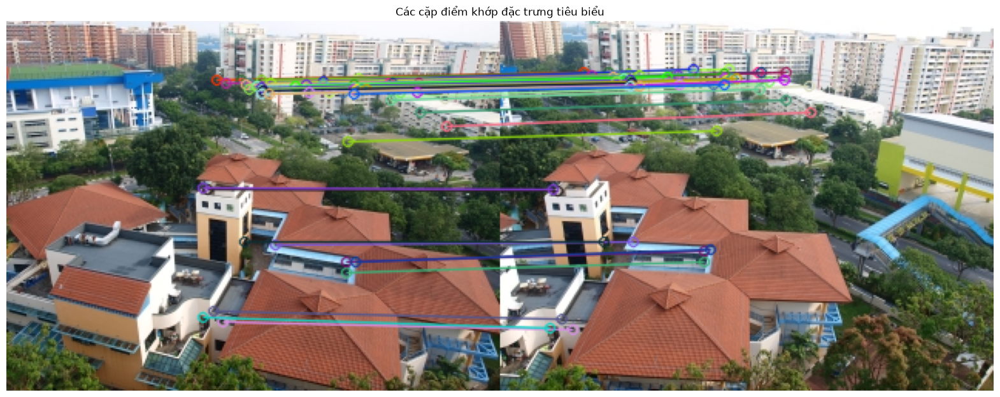

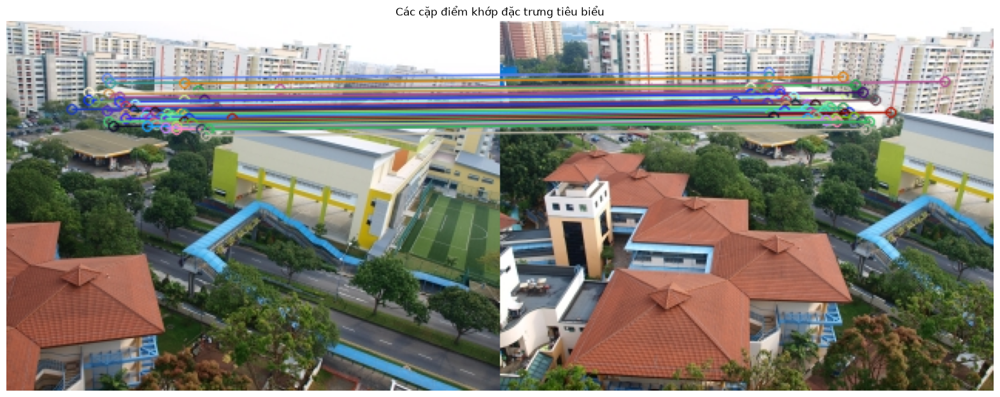

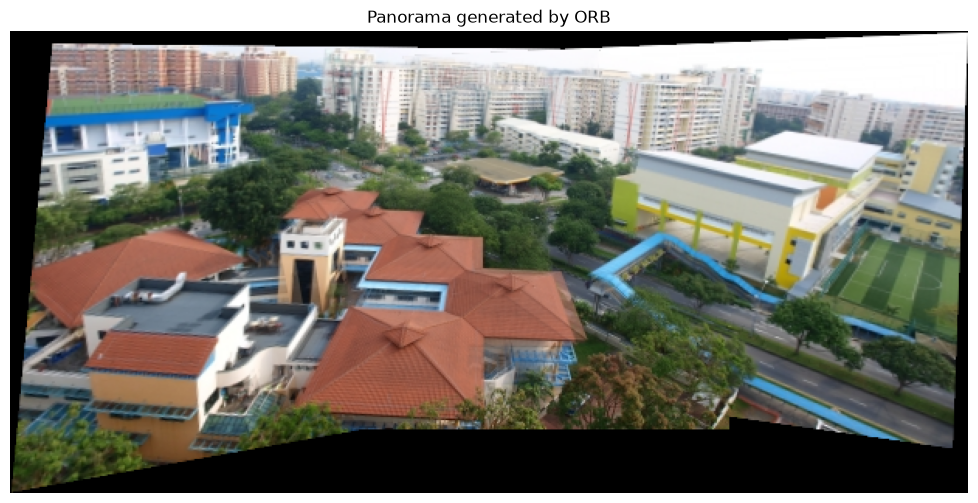


========================= AKAZE =========================


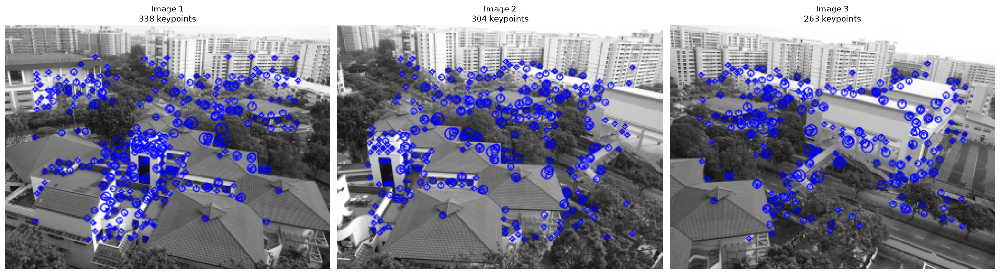

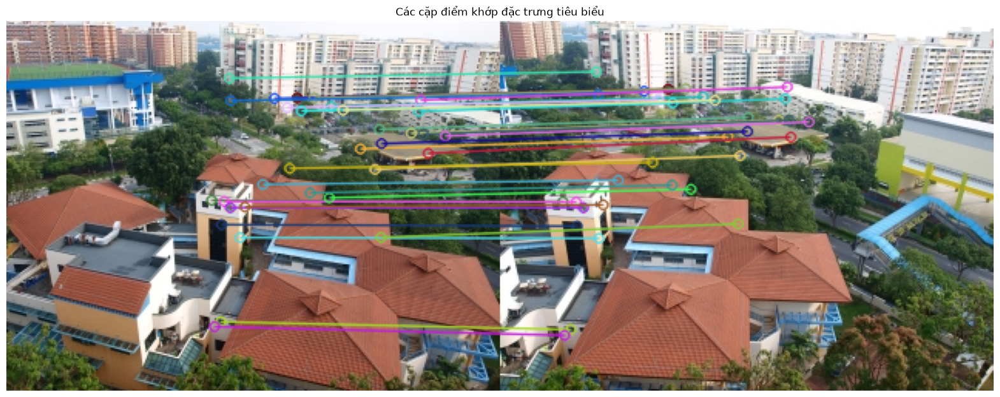

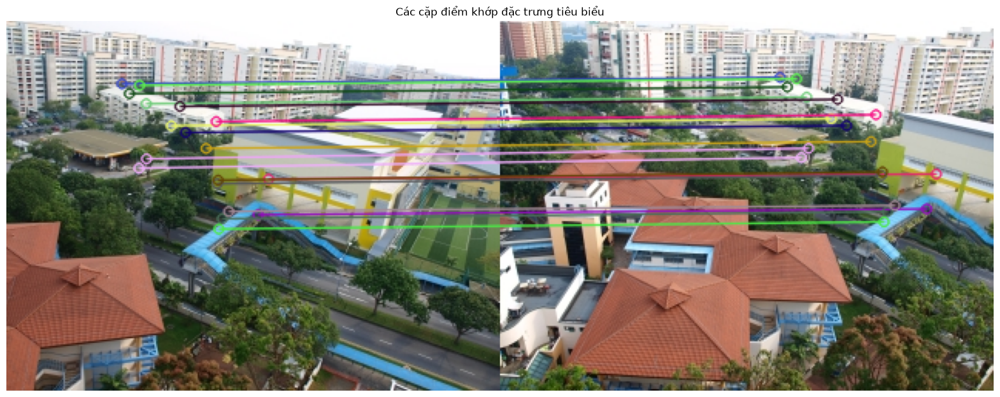

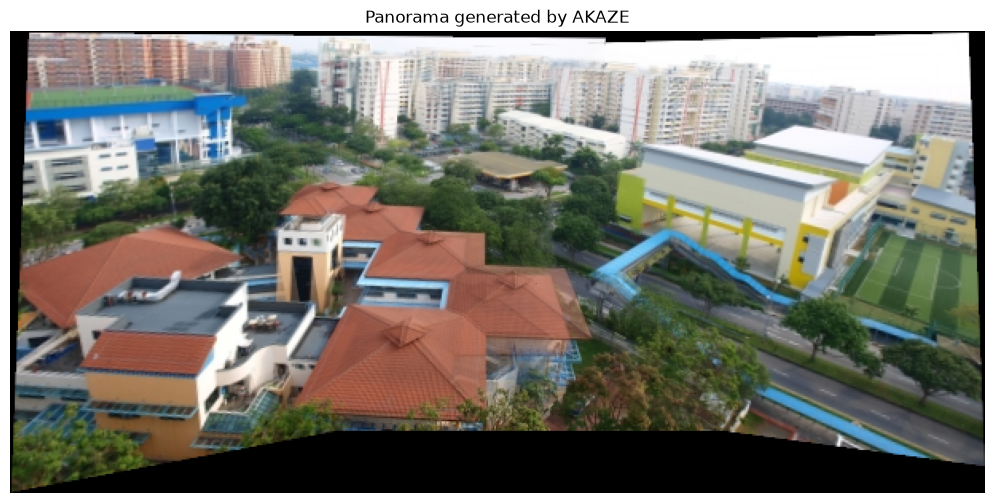

Metric,Keypoints,Good Matches (1->2),Good Matches (3->2),RANSAC Inliers (1->2),RANSAC Inliers (3->2),Inlier Ratio (1->2),Inlier Ratio (3->2),Execution Time (s)
Algorithm,,,,,,,,
SIFT,"[914, 890, 778]",170,91,166,83,97.65%,91.21%,2.6246
ORB,"[2637, 2627, 2444]",248,138,247,138,99.60%,100.00%,1.9034
AKAZE,"[338, 304, 263]",32,18,32,18,100.00%,100.00%,1.8494


In [4]:
all_metrics = []

for algo in ['SIFT', 'ORB', 'AKAZE']:
    metrics, panaroma = images_stitching(
        img1, img2, img3=img3,
        algo=algo,
        show_keypoints=True,
        show_matches=True,
        show_panorama=True,
        blending="FEATHER"
    )

    df_metrics = pd.DataFrame(metrics)
    df_metrics = df_metrics.set_index('Metric').T
    df_metrics['Algorithm'] = algo

    all_metrics.append(df_metrics)

df_summary = pd.concat(all_metrics, ignore_index=True)

# Đưa Algorithm lên đầu
df_summary = df_summary.set_index('Algorithm')

display.display(df_summary)

# Robustness test
## Low-light picture

### 4.1. Chuẩn bị dữ liệu: điều kiện thiếu sáng

Nạp và hiển thị cặp ảnh thiếu sáng để xác nhận dữ liệu đầu vào. So với ảnh gốc, điều kiện này có thể làm giảm độ tương phản và khiến detector khó tìm đặc trưng ổn định.

Cần đảm bảo hai ảnh vẫn chụp cùng cảnh, có vùng chồng lấp, và khác biệt chính là mức sáng; nếu đồng thời thay đổi nhiều yếu tố thì khó quy kết nguyên nhân cho ánh sáng.

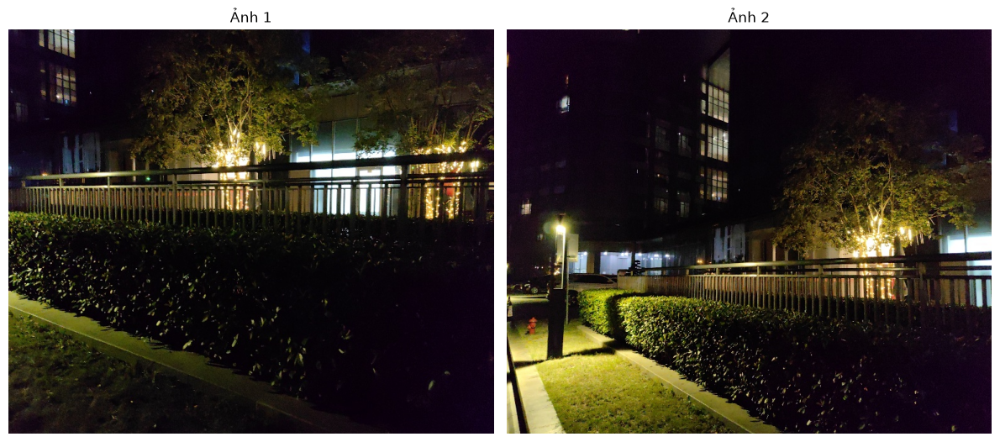

In [5]:
# Tu dong doc lai file anh nguon neu bien img1 hoac img2 chua duoc dinh nghia
lowlight1_path = 'input/robust_lowlight_01.jpg'
lowlight2_path = 'input/robust_lowlight_02.jpg'

if 'lowlight1' not in globals() and os.path.exists(lowlight1_path):
    lowlight1 = cv2.imread(lowlight1_path)
if 'lowlight2' not in globals() and os.path.exists(lowlight2_path):
    lowlight2 = cv2.imread(lowlight2_path)

lowlight_set = [lowlight1, lowlight2]

# Hien thi truc quan ba anh thu nghiem
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(cv2.cvtColor(lowlight1, cv2.COLOR_BGR2RGB))
axes[0].set_title("Ảnh 1")
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(lowlight2, cv2.COLOR_BGR2RGB))
axes[1].set_title("Ảnh 2")
axes[1].axis('off')

plt.tight_layout()
plt.show()

### 4.2. So sánh thuật toán trong điều kiện thiếu sáng

Chạy cùng pipeline và cùng ngưỡng tham số cho SIFT, ORB, AKAZE trên cặp ảnh thiếu sáng. Bảng chỉ số giúp kiểm tra thuật toán nào còn tìm được đủ đặc trưng tương ứng và có nhiều inlier hình học hơn.

Đối chiếu kết quả với benchmark ảnh gốc; quan sát matches và panorama để phát hiện trường hợp chỉ số có vẻ tốt nhưng homography hoặc vùng ghép vẫn không hợp lý.


========================= SIFT =========================


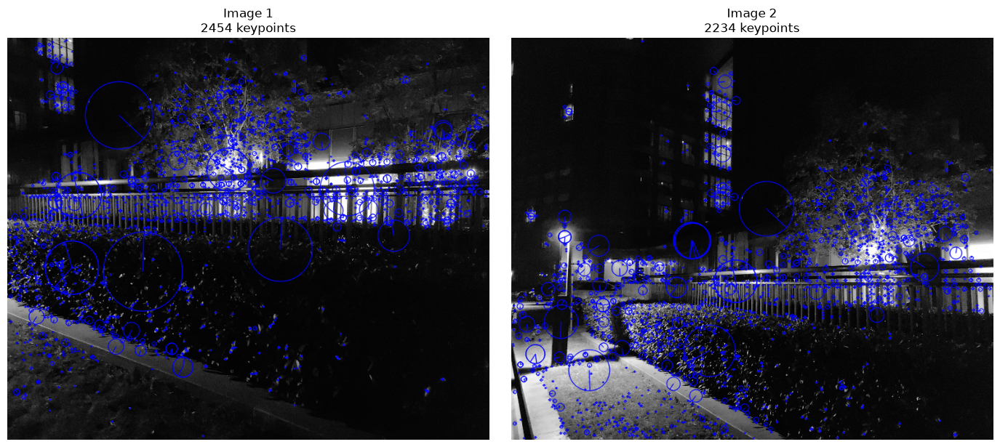

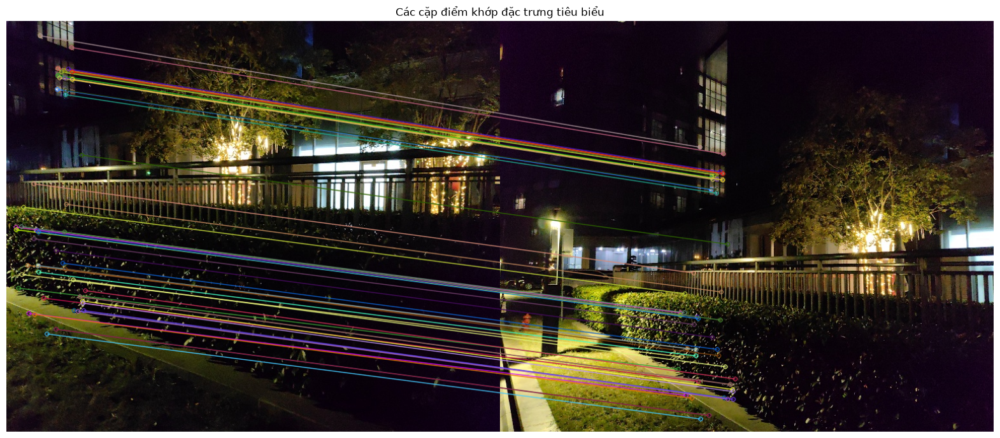

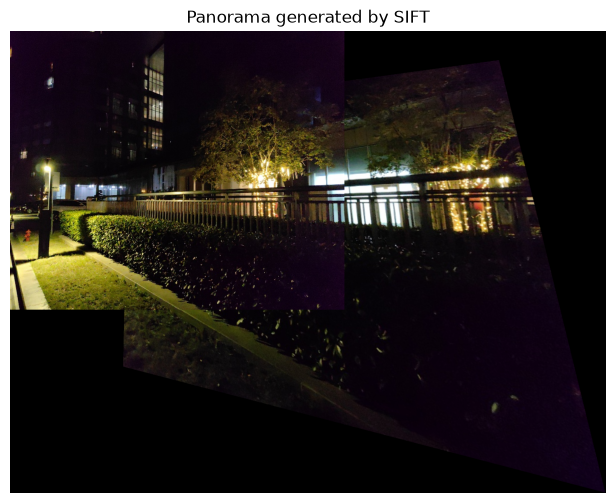


========================= ORB =========================


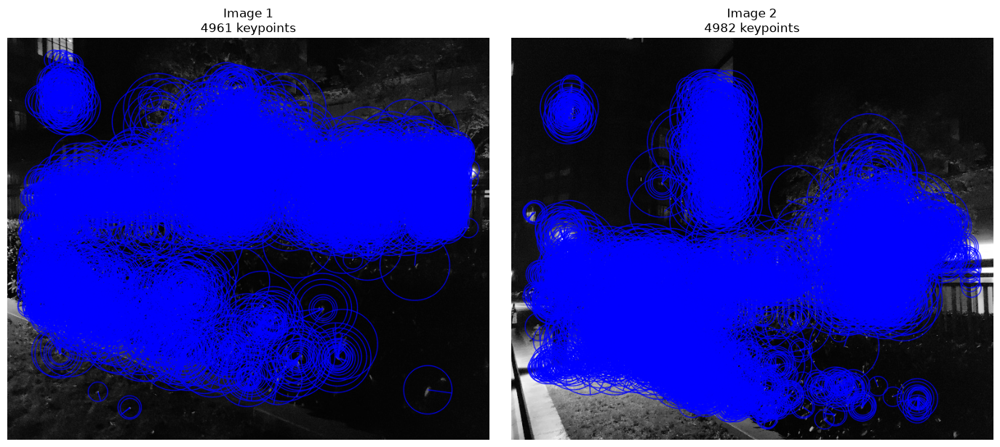

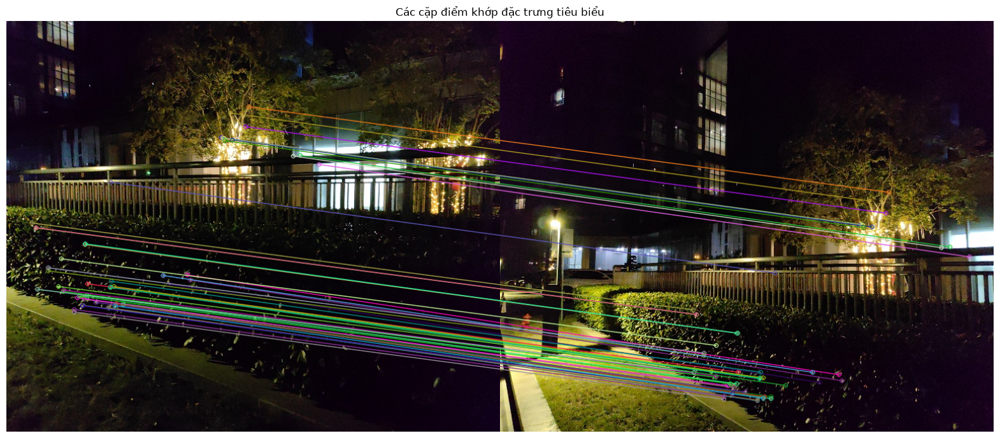

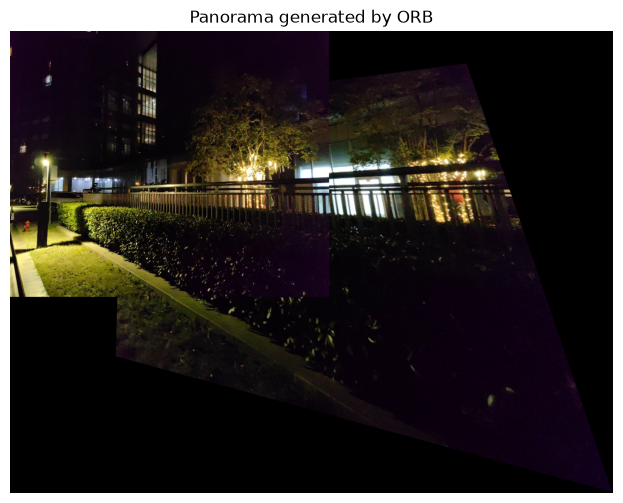


========================= AKAZE =========================


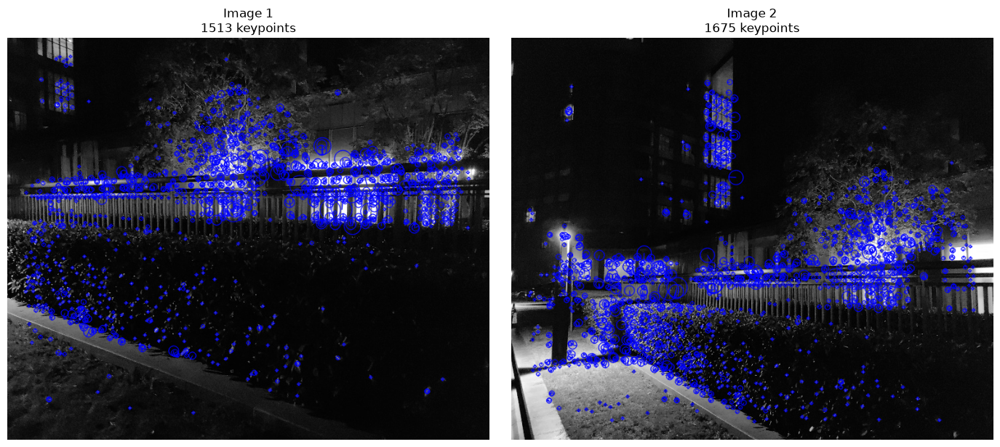

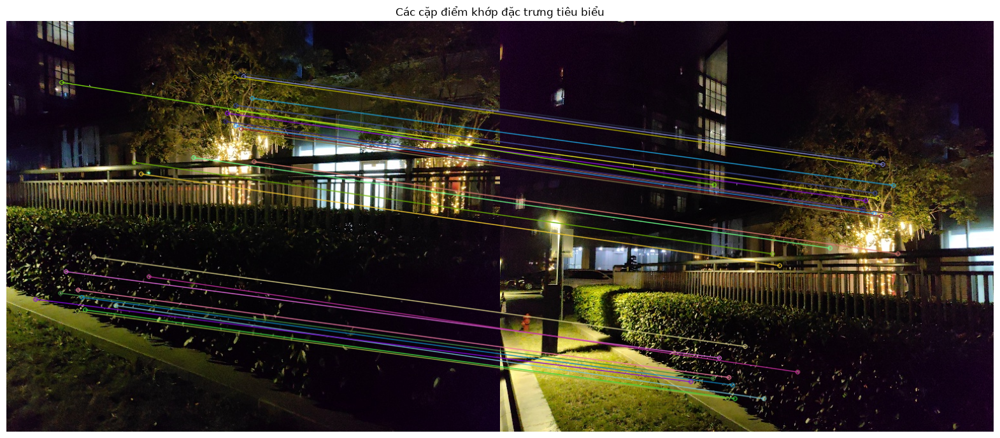

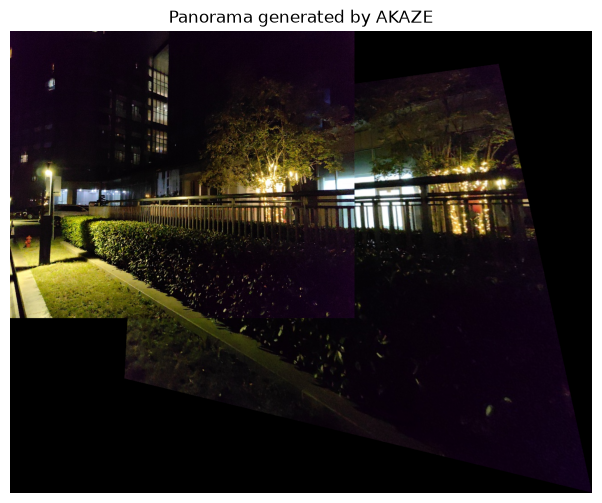

Metric,Keypoints,Good Matches (1->2),RANSAC Inliers (1->2),Inlier Ratio (1->2),Execution Time (s)
Algorithm,,,,,
SIFT,"[2454, 2234]",117,101,86.32%,1.5179
ORB,"[4961, 4982]",121,99,81.82%,1.7549
AKAZE,"[1513, 1675]",28,21,75.00%,1.5748


In [6]:
all_metrics = []

for algo in ['SIFT', 'ORB', 'AKAZE']:
    metrics, panorama = images_stitching(
        lowlight1, lowlight2,
        algo=algo,
        show_keypoints=True,
        show_matches=True,
        show_panorama=True
    )

    df_metrics = pd.DataFrame(metrics)
    df_metrics = df_metrics.set_index('Metric').T
    df_metrics['Algorithm'] = algo

    all_metrics.append(df_metrics)

df_summary = pd.concat(all_metrics, ignore_index=True)

# Đưa Algorithm lên đầu
df_summary = df_summary.set_index('Algorithm')

display.display(df_summary)

## Illumination/ Color Inconsistent

### 5.1. Chuẩn bị dữ liệu: ánh sáng/màu sắc không đồng nhất

Nạp và hiển thị cặp ảnh có độ sáng hoặc màu sắc khác nhau. Thí nghiệm này tập trung vào mức độ ổn định của phát hiện và matching khi cùng cảnh có phân bố cường độ/màu khác nhau.

Nếu bộ ảnh còn khác cả góc nhìn hoặc nội dung chuyển động, ghi nhận đây là yếu tố gây nhiễu khi rút ra kết luận.

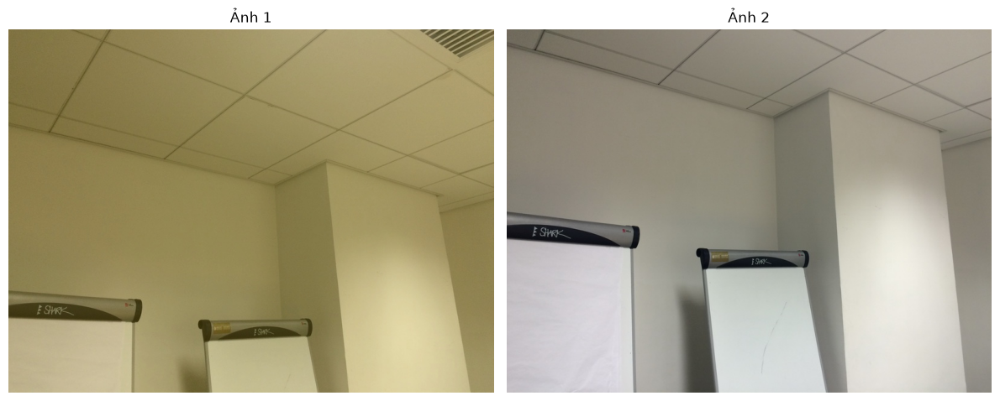

In [7]:
# Tu dong doc lai file anh nguon neu bien img1 hoac img2 chua duoc dinh nghia
illumination1_path = 'input/robust_illumination_01.jpg'
illumination2_path = 'input/robust_illumination_02.jpg'

if 'illumination1' not in globals() and os.path.exists(illumination1_path):
    illumination1 = cv2.imread(illumination1_path)
if 'illumination2' not in globals() and os.path.exists(illumination2_path):
    illumination2 = cv2.imread(illumination2_path)

illumination_set = [illumination1, illumination2]

# Hien thi truc quan ba anh thu nghiem
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(cv2.cvtColor(illumination1, cv2.COLOR_BGR2RGB))
axes[0].set_title("Ảnh 1")
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(illumination2, cv2.COLOR_BGR2RGB))
axes[1].set_title("Ảnh 2")
axes[1].axis('off')

plt.tight_layout()
plt.show()


### 5.2. So sánh thuật toán khi ánh sáng/màu sắc khác nhau

Chạy SIFT, ORB và AKAZE với cùng tham số trên cặp ảnh đã chuẩn bị. So sánh số keypoints, good matches, RANSAC inliers, inlier ratio và thời gian chạy với trường hợp cơ sở.

Khi nhận xét, tách biệt hai vấn đề: **matching có tìm được tương ứng không** và **các tương ứng có nhất quán với một homography không**.


========================= SIFT =========================


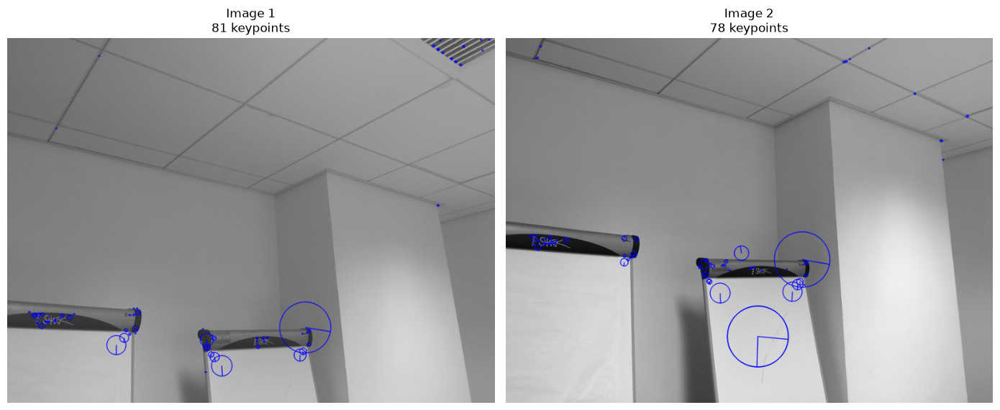

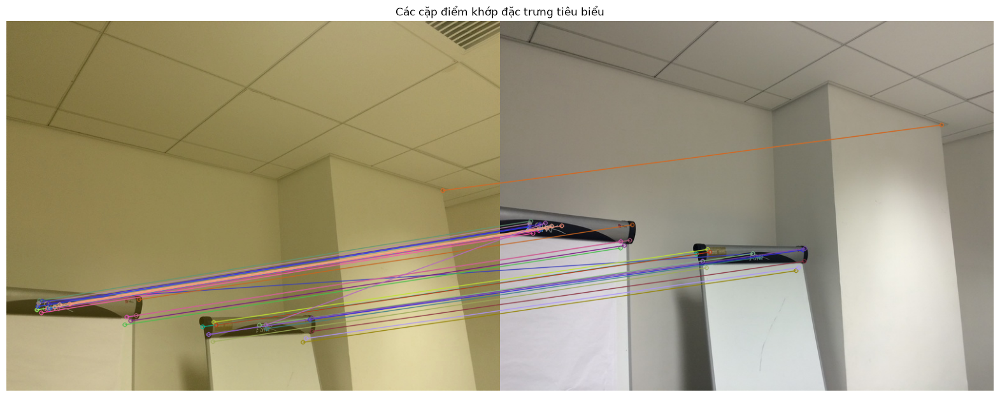

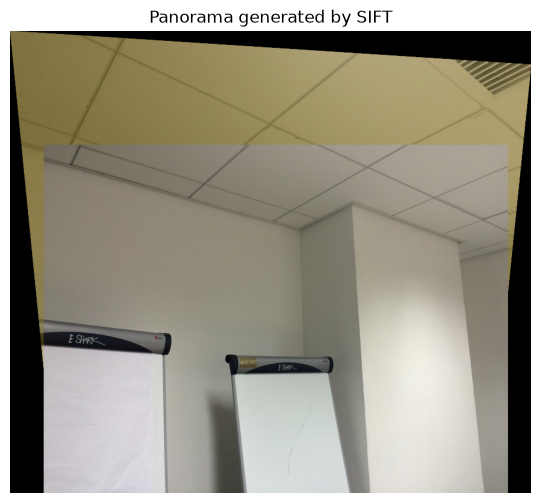


========================= ORB =========================


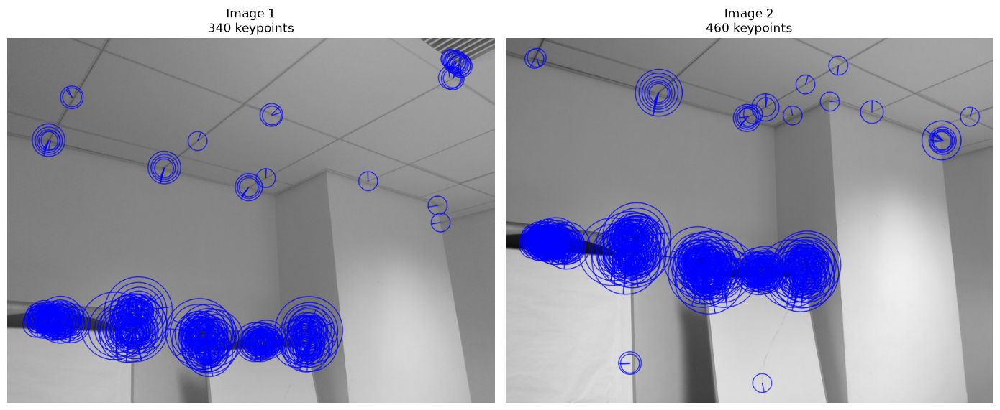

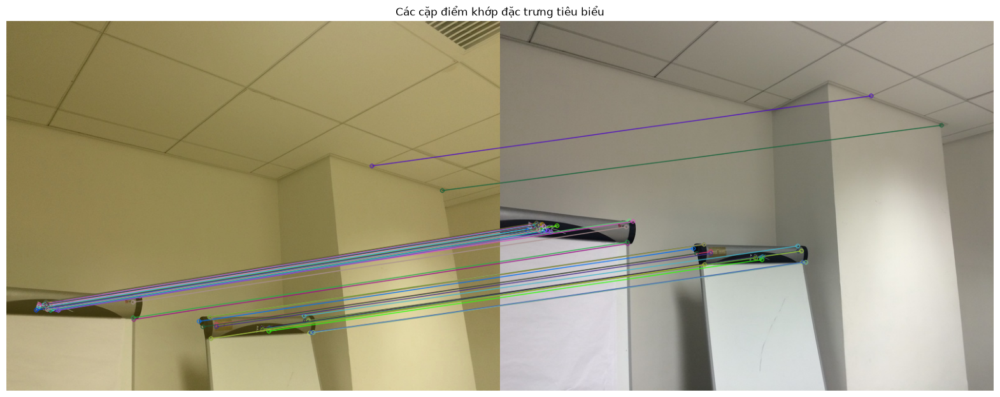

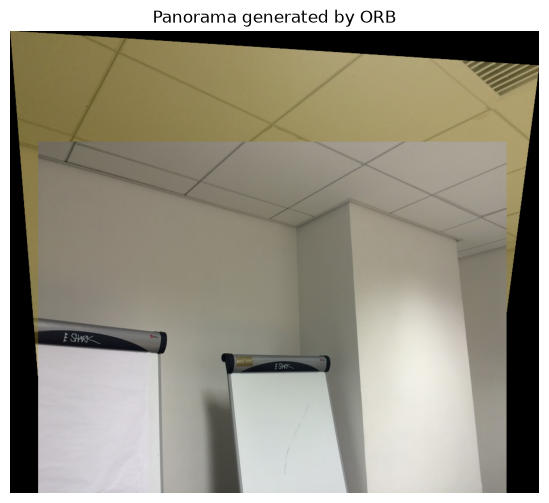


========================= AKAZE =========================


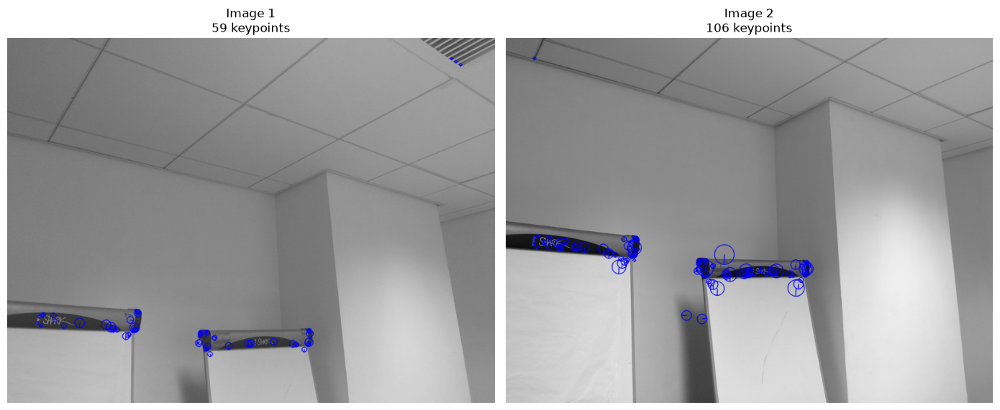

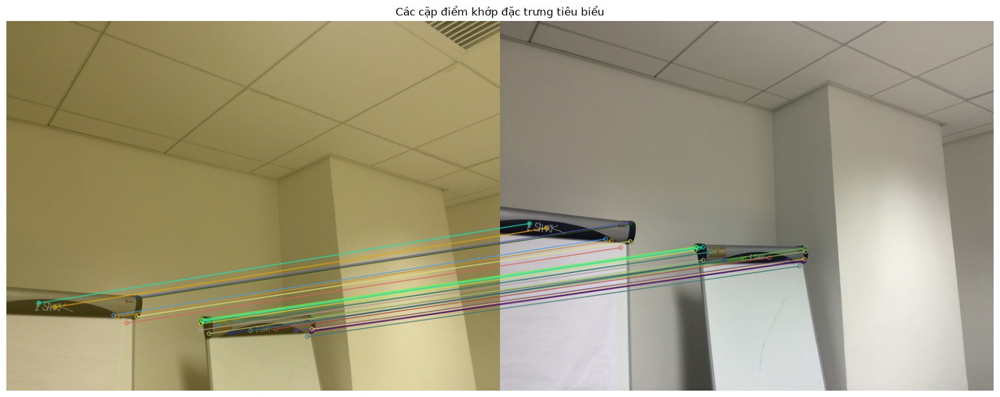

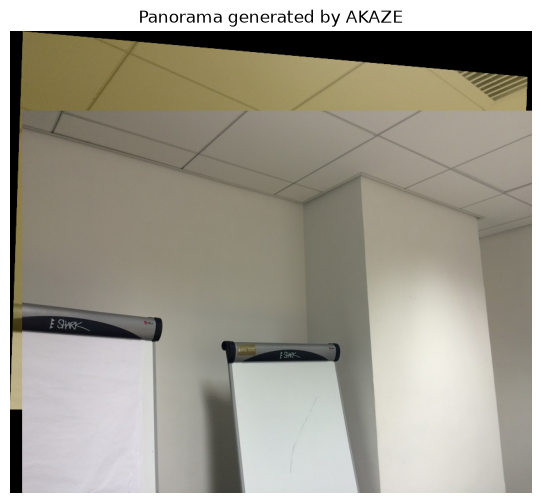

Metric,Keypoints,Good Matches (1->2),RANSAC Inliers (1->2),Inlier Ratio (1->2),Execution Time (s)
Algorithm,,,,,
SIFT,"[81, 78]",35,33,94.29%,1.616
ORB,"[340, 460]",84,82,97.62%,1.2975
AKAZE,"[59, 106]",28,26,92.86%,1.3283


In [8]:
all_metrics = []

for algo in ['SIFT', 'ORB', 'AKAZE']:
    metrics, panorama = images_stitching(
        illumination1, illumination2,
        algo=algo,
        show_keypoints=True,
        show_matches=True,
        show_panorama=True
    )

    df_metrics = pd.DataFrame(metrics)
    df_metrics = df_metrics.set_index('Metric').T
    df_metrics['Algorithm'] = algo

    all_metrics.append(df_metrics)

df_summary = pd.concat(all_metrics, ignore_index=True)

# Đưa Algorithm lên đầu
df_summary = df_summary.set_index('Algorithm')

display.display(df_summary)

## Large homography (large different perspective)

### 6.1. Chuẩn bị dữ liệu: khác biệt phối cảnh lớn

Nạp và hiển thị cặp ảnh có khác biệt phối cảnh/góc nhìn lớn. Trường hợp này kiểm tra khả năng duy trì các tương ứng đặc trưng khi hình dạng biểu kiến của cảnh thay đổi mạnh.

Homography mô hình hóa quan hệ phối cảnh giữa hai mặt phẳng (hoặc cảnh gần phẳng); với parallax mạnh hay vật thể ở nhiều độ sâu, một homography duy nhất có thể không căn chỉnh tốt toàn bộ ảnh.

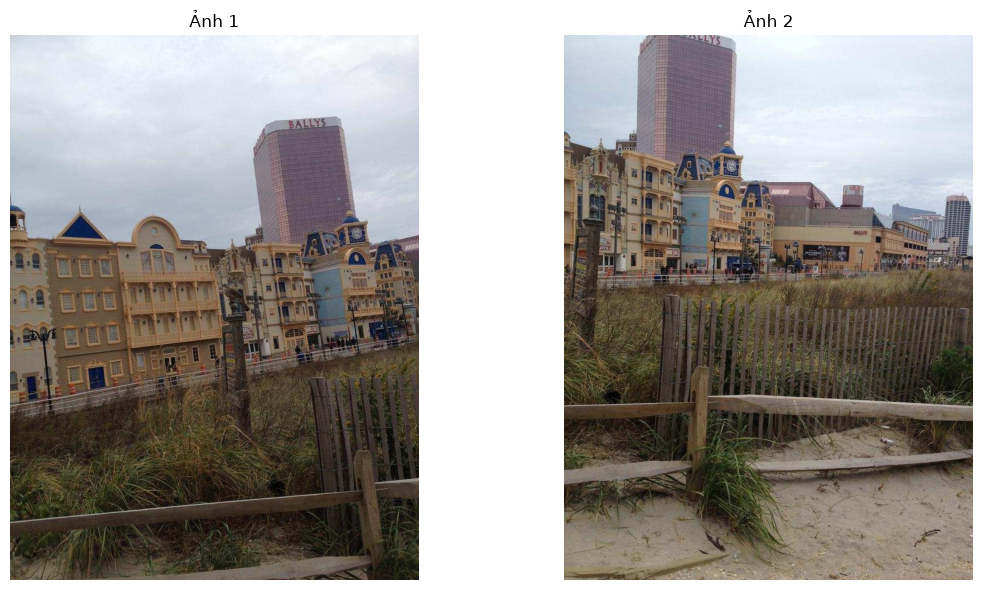

In [9]:
# Tu dong doc lai file anh nguon neu bien img1 hoac img2 chua duoc dinh nghia
perspective1_path = 'input/robust_perspective_01.jpg'
perspective2_path = 'input/robust_perspective_02.jpg'

if 'perspective1' not in globals() and os.path.exists(perspective1_path):
    perspective1 = cv2.imread(perspective1_path)
if 'perspective2' not in globals() and os.path.exists(perspective2_path):
    perspective2 = cv2.imread(perspective2_path)

perspective_set = [perspective1, perspective2]

# Hien thi truc quan ba anh thu nghiem
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(cv2.cvtColor(perspective1, cv2.COLOR_BGR2RGB))
axes[0].set_title("Ảnh 1")
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(perspective2, cv2.COLOR_BGR2RGB))
axes[1].set_title("Ảnh 2")
axes[1].axis('off')

plt.tight_layout()
plt.show()

### 6.2. So sánh thuật toán trong điều kiện khác biệt phối cảnh lớn

Chạy cùng pipeline với SIFT, ORB và AKAZE, sau đó tổng hợp chỉ số và kiểm tra trực quan. Đặc biệt chú ý:
- số lượng và phân bố không gian của matches;
- số lượng/inlier ratio sau RANSAC;
- vùng bị kéo giãn hoặc lệch trong panorama.

Kết quả cần được diễn giải như một thí nghiệm trên cặp ảnh cụ thể, không phải kết luận tuyệt đối cho mọi trường hợp phối cảnh.


========================= SIFT =========================


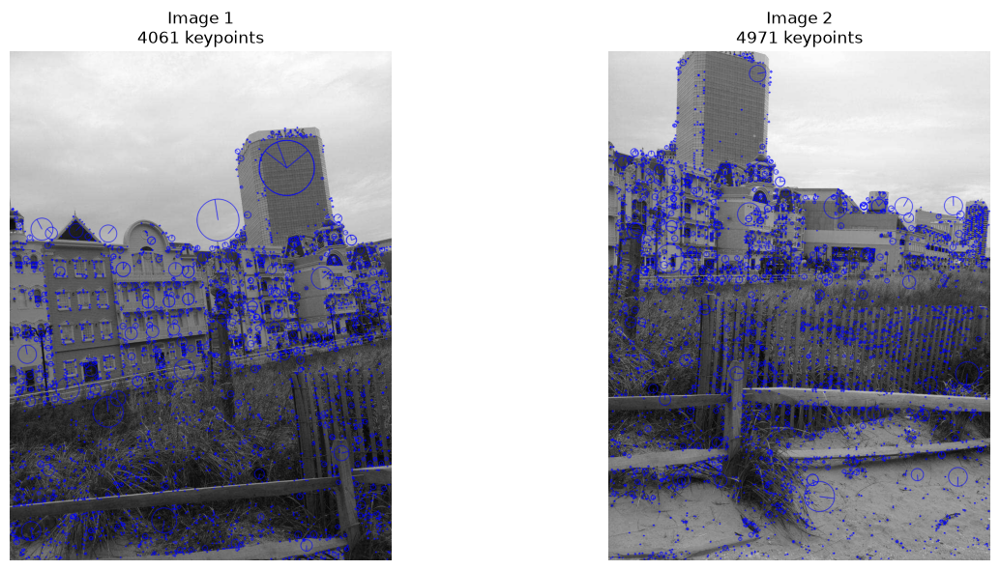

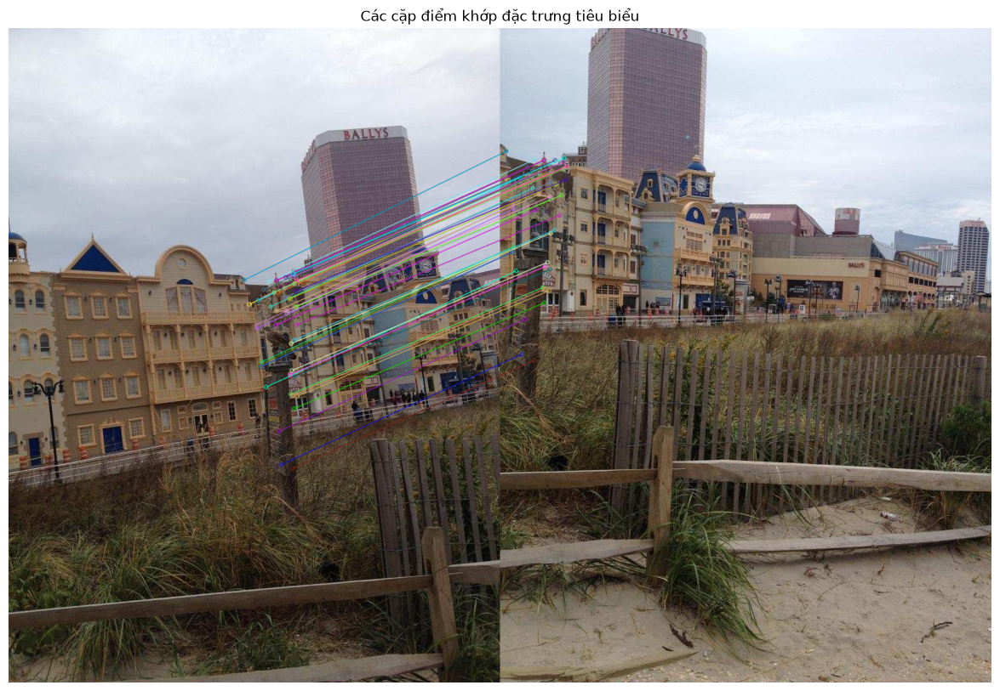

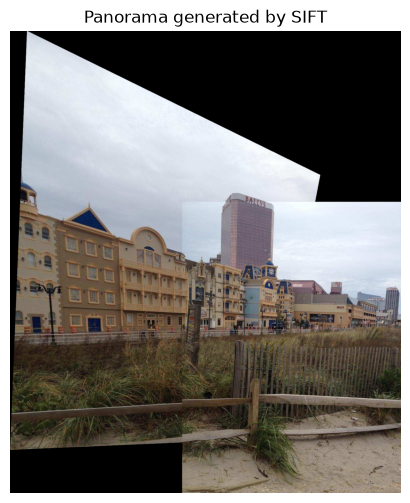


========================= ORB =========================


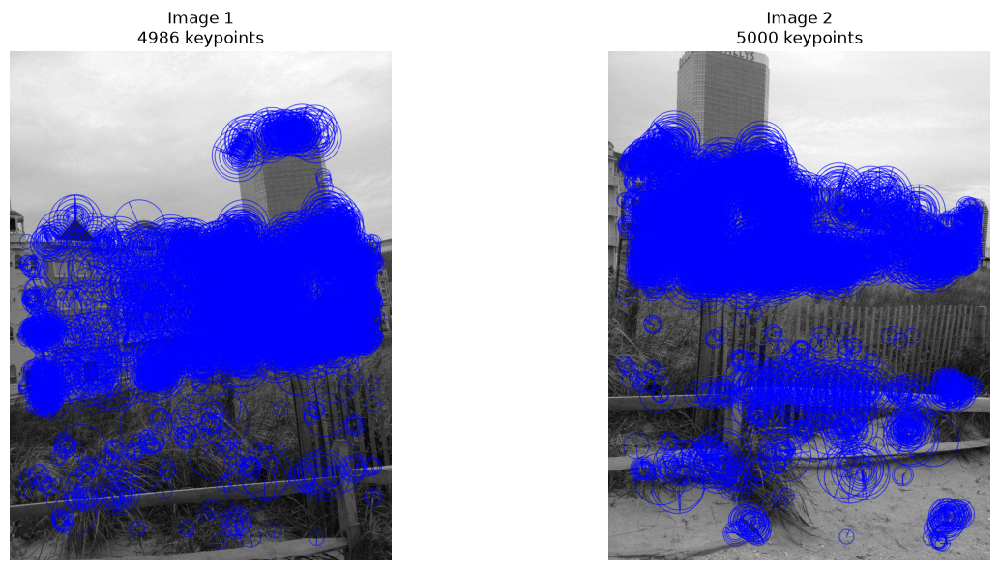

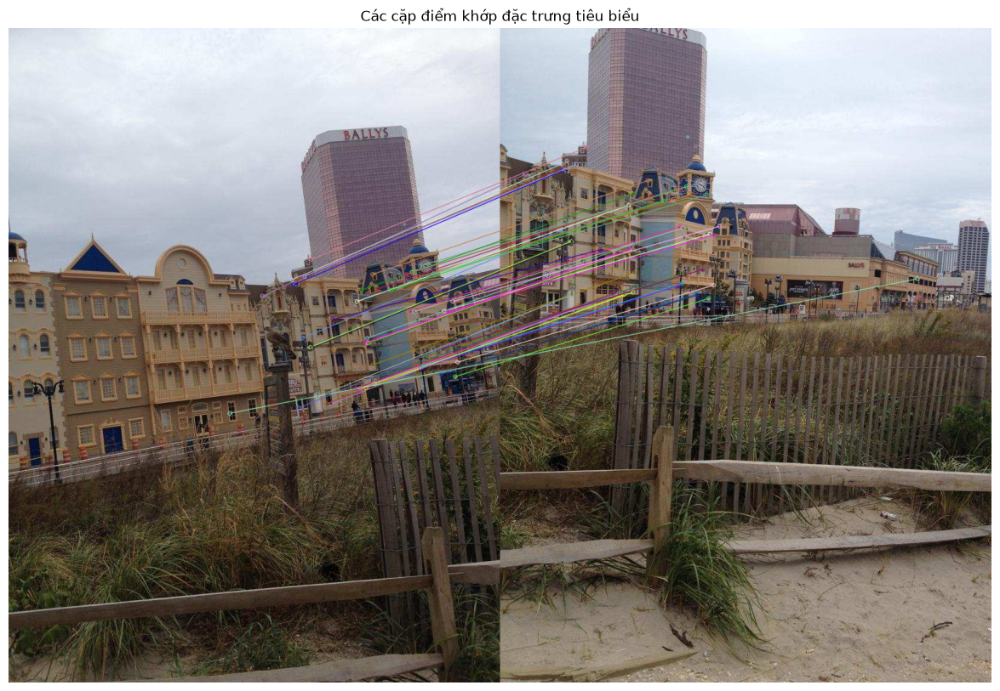

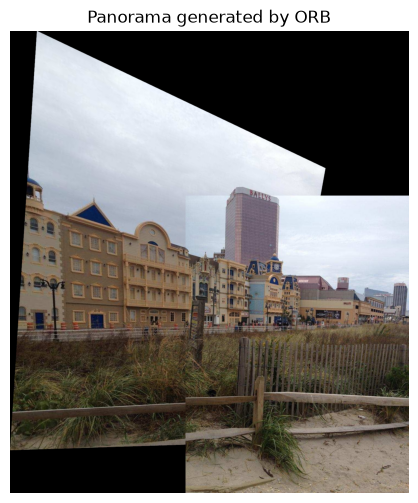


========================= AKAZE =========================


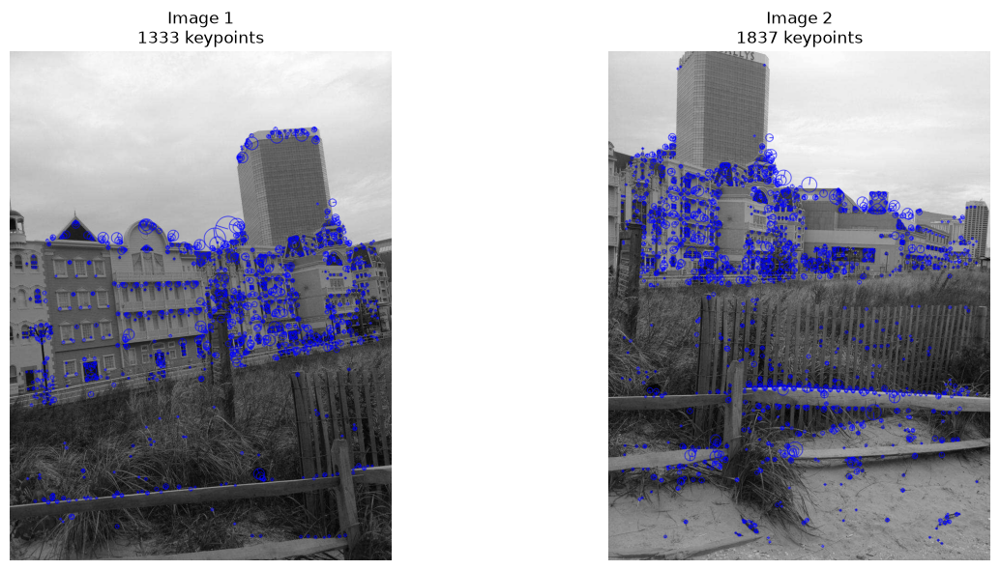

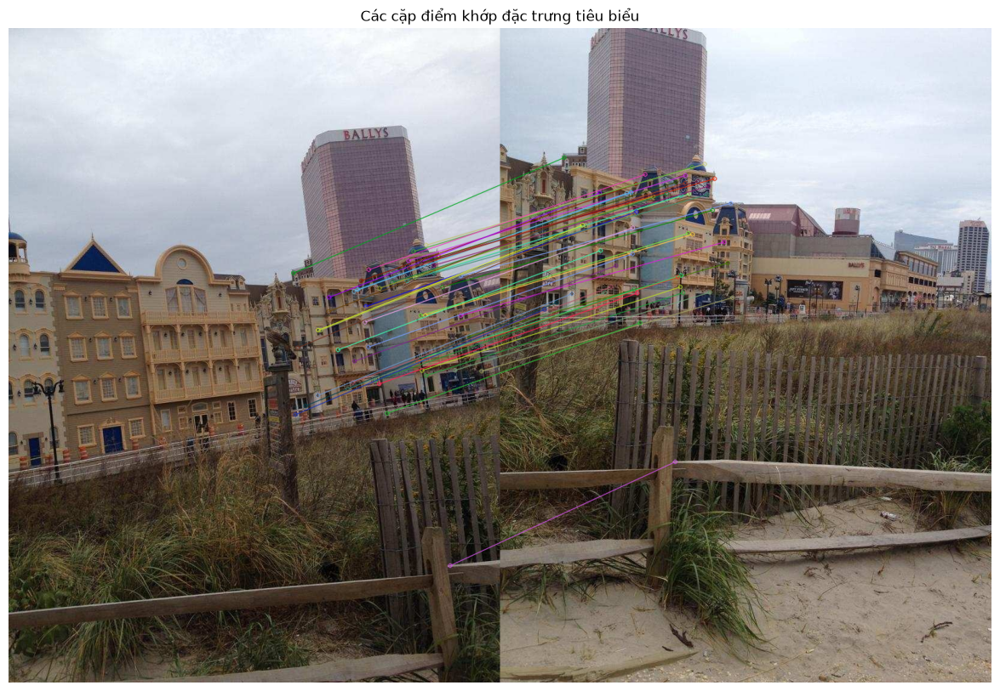

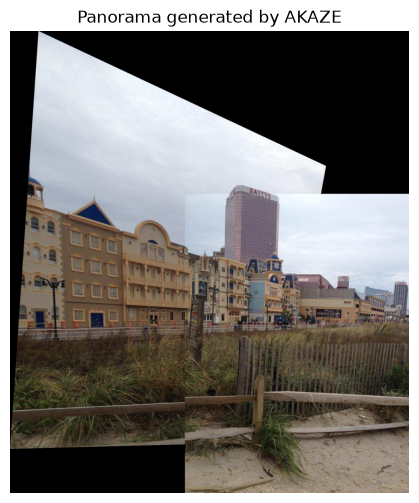

Metric,Keypoints,Good Matches (1->2),RANSAC Inliers (1->2),Inlier Ratio (1->2),Execution Time (s)
Algorithm,,,,,
SIFT,"[4061, 4971]",454,407,89.65%,2.0498
ORB,"[4986, 5000]",518,508,98.07%,1.939
AKAZE,"[1333, 1837]",154,148,96.10%,1.8326


In [10]:
all_metrics = []

for algo in ['SIFT', 'ORB', 'AKAZE']:
    metrics, panorama = images_stitching(
        perspective1, perspective2,
        algo=algo,
        show_keypoints=True,
        show_matches=True,
        show_panorama=True
    )

    df_metrics = pd.DataFrame(metrics)
    df_metrics = df_metrics.set_index('Metric').T
    df_metrics['Algorithm'] = algo

    all_metrics.append(df_metrics)

df_summary = pd.concat(all_metrics, ignore_index=True)

# Đưa Algorithm lên đầu
df_summary = df_summary.set_index('Algorithm')

display.display(df_summary)

# 7. So sánh kỹ thuật blending

Các thí nghiệm trước dùng **overlay**: pixel của ảnh này được ưu tiên hơn ảnh kia trong vùng chồng lấp. Cách này đơn giản nhưng có thể tạo đường nối rõ, đặc biệt khi hai ảnh lệch sáng hoặc còn sai số căn chỉnh.

Phần này cố định **cùng một cặp ảnh và cùng homography**, chỉ thay đổi cách kết hợp pixel để tách ảnh hưởng của blending khỏi ảnh hưởng của feature matching/homography.

Các phương pháp dự kiến:
1. **Overlay (baseline):** ưu tiên ảnh thứ hai tại vùng chồng lấp; dùng làm mốc so sánh.
2. **Average blending:** lấy trung bình pixel ở vùng chồng lấp; dễ thực hiện nhưng có thể tạo bóng đôi nếu ảnh chưa căn chỉnh chính xác.
3. **Feather blending:** dùng trọng số thay đổi dần theo khoảng cách tới biên mask; thường chuyển tiếp mềm hơn average/overlay, nhưng không sửa được sai lệch hình học.

Giới hạn phạm vi: triển khai trước với **hai ảnh** để kiểm soát thí nghiệm. Khi đã kiểm tra được kết quả, có thể mở rộng sang ba ảnh. Các phương pháp không được kỳ vọng khắc phục parallax hay ghosting do homography sai.

## 7.2. Chạy so sánh blending

Dùng một thuật toán căn chỉnh cố định (mặc định SIFT) để so sánh ba cách kết hợp pixel. Nếu muốn đánh giá blending độc lập hơn với lựa chọn detector, có thể chạy lại với ORB/AKAZE nhưng phải ghi rõ rằng homography có thể khác nhau giữa các thuật toán.

Khi nhận xét, tập trung vào:
- độ rõ của đường nối;
- độ sáng/màu sắc trong vùng chồng lấp;
- hiện tượng bóng đôi hoặc đường biên bị nhòe;
- phần ảnh bị mất hoặc vùng đen bất thường.

**Không chỉ dựa vào ảnh đẹp/xấu:** nếu panorama bị lệch do homography, blending không thể tự sửa lỗi căn chỉnh đó.

In [11]:
all_metrics = []
all_panoramas = {}

datasets = {
    "Sample": sample_set,
    "Lowlight": lowlight_set,
    "Illumination": illumination_set
}

for set_name, imgs_set in datasets.items():
    set_metrics = []
    set_panoramas = {}

    for algo in ALGORITHM:
        for blend_mod in BLENDING:
            metrics, panorama = images_stitching(
                imgs_set[0],
                imgs_set[1],
                img3=imgs_set[2] if len(imgs_set) == 3 else None,
                algo=algo,
                blending=blend_mod,
                show_keypoints=False,
                show_matches=False,
                show_panorama=False,
                verbose=False
            )

            # Lưu panorama theo Algorithm và Blending
            set_panoramas[(algo, blend_mod)] = panorama

            # Chuyển metrics thành một hàng
            df_metrics = pd.DataFrame(metrics)
            df_metrics = df_metrics.set_index("Metric").T
            df_metrics["Dataset"] = set_name
            df_metrics["Algorithm"] = algo
            df_metrics["Blending"] = blend_mod

            set_metrics.append(df_metrics)

    all_metrics.extend(set_metrics)
    all_panoramas[set_name] = set_panoramas

df_summary = pd.concat(all_metrics, ignore_index=True)

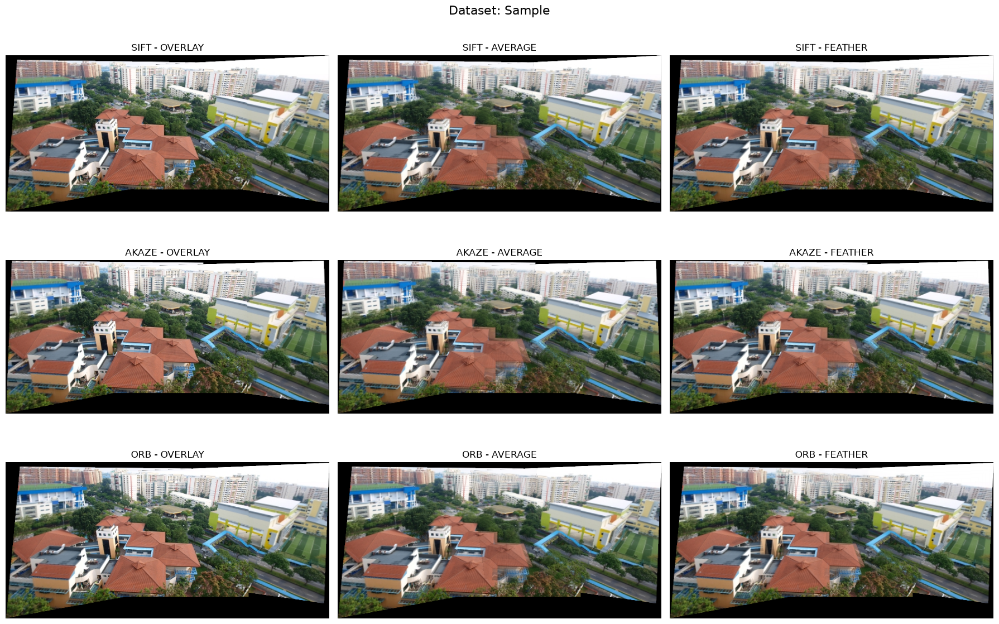

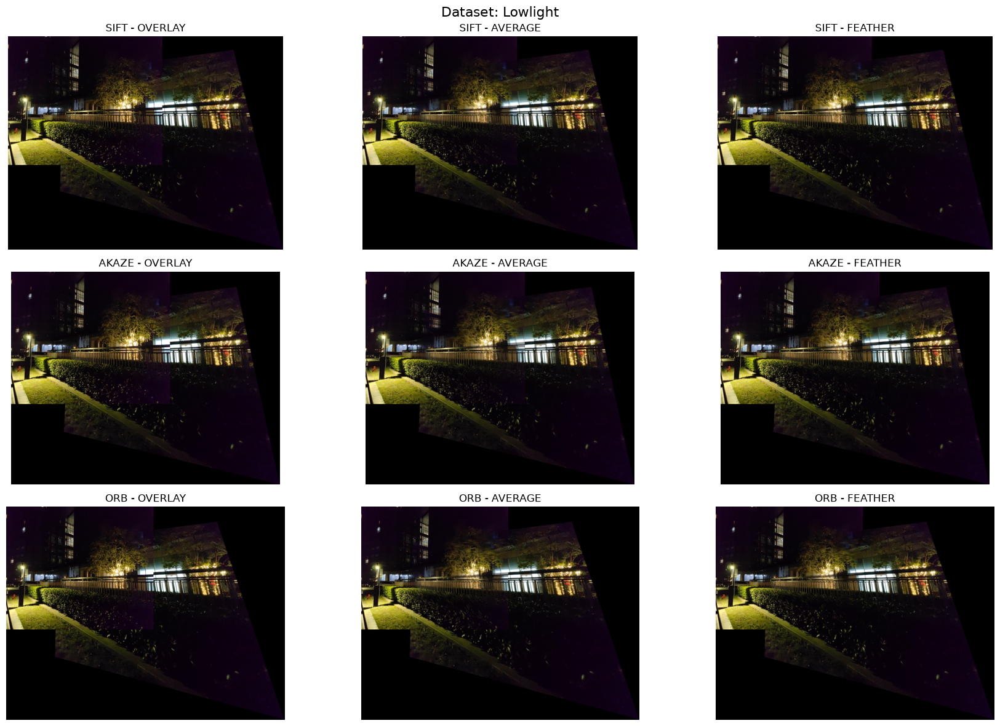

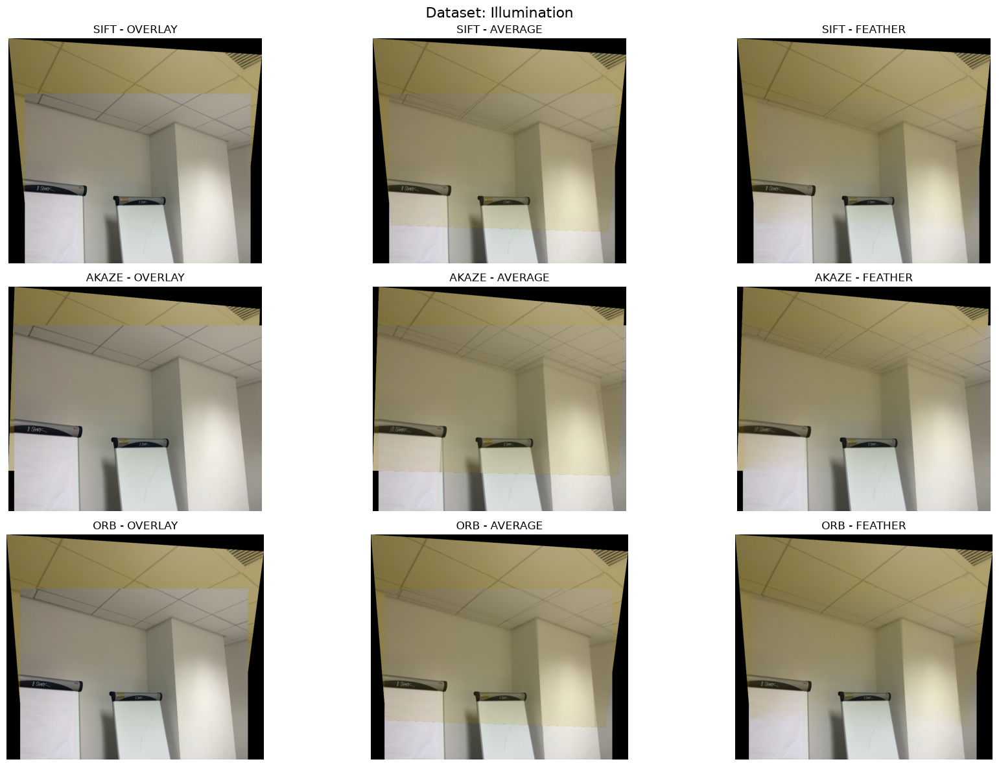

In [12]:
for set_name, panoramas in all_panoramas.items():
    fig, axes = plt.subplots(
        len(ALGORITHM),
        len(BLENDING),
        figsize=(6 * len(BLENDING), 4 * len(ALGORITHM)),
        squeeze=False
    )

    fig.suptitle(f"Dataset: {set_name}", fontsize=16)

    for i, algo in enumerate(ALGORITHM):
        for j, blend_mod in enumerate(BLENDING):
            ax = axes[i, j]
            panorama = panoramas[(algo, blend_mod)]

            if panorama is not None:
                ax.imshow(cv2.cvtColor(panorama, cv2.COLOR_BGR2RGB))
                ax.set_title(f"{algo} - {blend_mod}")
            else:
                ax.set_title(f"{algo} - {blend_mod}: Failed")

            ax.axis("off")

    plt.tight_layout()
    plt.show()